# Infrastruktur und Hauspreise in King County 2014/15

**Leitfrage:** Wie hängen Fluglärm, die Nähe zu Boeing-Werken und der Zugang zur damaligen Flughafenbahn mit Hauspreisen zusammen, wenn Hausmerkmale und Lage berücksichtigt werden?

| Teil | Rolle in diesem Notebook |
|---|---|
| A Fluglärm | Hauptanalyse |
| B Boeing-Nähe | Ergänzung: räumliche Verzerrung |
| C Flughafenbahn (Central Link 2015) | explorative Erweiterung |

**Wichtig vorab:** Das sind Beobachtungsdaten. Alle Ergebnisse sind Zusammenhänge, keine kausalen Effekte. Die Modelle wurden explorativ gewählt, nicht vorab festgelegt.

**Grundlage:** Ein Analysepaket von ChatGPT/Codex (`infrastruktur_daten/UEBERGABE_referenzwerte.txt`) liefert Methode, Geometrien und Referenzwerte. Alle Zahlen hier werden aus der Original-CSV und den Geometrien neu berechnet. Abschnitt D vergleicht sie mit den Referenzwerten. Die Notebooks `04_eda.ipynb` und `04_eda_reviewed.ipynb` sowie die Original-CSV bleiben unverändert.

## 0. Setup

In [1]:
import hashlib
import json
import os
import warnings
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import shapely
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from shapely.geometry import shape
from shapely.ops import transform

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.facecolor": "white", "figure.facecolor": "w",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: "%.3f" % x)

SEED = 42                          # es gibt keine Zufallsverfahren, Seed nur der Vollständigkeit halber
np.random.seed(SEED)
EINGABE = "infrastruktur_daten"
AUSGABE = "bilder/infrastruktur"  # eigener Ausgabeordner dieses Notebooks
os.makedirs(AUSGABE, exist_ok=True)
BLAU, ROT, GRAU = "#2b6cb0", "#c05621", "#a0aec0"

for paket in ["pandas", "numpy", "statsmodels", "scipy", "shapely", "pyproj", "matplotlib"]:
    print(f"{paket:12s} {version(paket)}")

pandas       3.0.3
numpy        2.4.6
statsmodels  0.15.0
scipy        1.17.1
shapely      2.2.0
pyproj       3.8.0
matplotlib   3.10.9


In [2]:
def speichern(fig, name):
    fig.savefig(f"{AUSGABE}/{name}.png", dpi=150, bbox_inches="tight")


def prozent(b):
    """Koeffizient eines Log-Preis-Modells als prozentualer Preisunterschied."""
    return 100 * np.expm1(b)


def schaetzen(name, formel, daten, merkmal, varianten):
    """OLS für log(Preis). Das Modell wird einmal aufgebaut, dann mit jeder Standardfehler-Variante geschätzt.
    varianten: dict Name -> None (HC3) oder Spalte für Clusterung."""
    modell = smf.ols(formel, daten)
    zeilen = []
    for vname, cluster in varianten.items():
        if cluster is None:
            fit = modell.fit(cov_type="HC3", use_t=True)
        else:
            fit = modell.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(daten[cluster])[0]}, use_t=True)
        unten, oben = fit.conf_int().loc[merkmal]
        zeilen.append({"modell": name, "unsicherheit": vname, "n": int(fit.nobs),
                       "prozent": prozent(fit.params[merkmal]), "ki_von": prozent(unten), "ki_bis": prozent(oben),
                       "p": fit.pvalues[merkmal], "r2": fit.rsquared})
    return zeilen


def forest(ax, tabelle, beschriftung, farbe=BLAU):
    y = np.arange(len(tabelle))
    ax.errorbar(tabelle.prozent, y, xerr=[tabelle.prozent - tabelle.ki_von, tabelle.ki_bis - tabelle.prozent],
                fmt="o", color=farbe, ecolor=GRAU, capsize=3)
    ax.set_yticks(y, beschriftung)
    ax.invert_yaxis()
    ax.axvline(0, color="#4a5568", linewidth=1, linestyle="--")
    ax.grid(axis="x", color="#e2e8f0")

## 1. Daten und Prüfungen

### 1.1 Original-CSV

In [3]:
QUELLE = "data/king_county.csv"
ERWARTET = "d08eaa479a137962dd43735b7b930a6553e675bb61e39671af0802c90d21c7af"  # Prüfsumme laut Übergabe
sha_vorher = hashlib.sha256(open(QUELLE, "rb").read()).hexdigest()
print("SHA-256 stimmt mit der Übergabe überein:", sha_vorher == ERWARTET)

df = pd.read_csv(QUELLE, parse_dates=["date"])
print("Verkäufe:", len(df), "| sale_id eindeutig:", df.sale_id.is_unique, "| Immobilien:", df.id.nunique())
print("Zeitraum:", df.date.min().date(), "bis", df.date.max().date())
print("Koordinaten: Breite", df.lat.min(), "bis", df.lat.max(), "| Länge", df.long.min(), "bis", df.long.max())
print("fehlende Koordinaten:", df[["lat", "long"]].isna().sum().sum())

SHA-256 stimmt mit der Übergabe überein: True
Verkäufe: 21597 | sale_id eindeutig: True | Immobilien: 21420
Zeitraum: 2014-05-02 bis 2015-05-27
Koordinaten: Breite 47.1559 bis 47.7776 | Länge -122.519 bis -121.315
fehlende Koordinaten: 0


### 1.2 Ausschluss und gemeinsame Merkmale

- **33 Schlafzimmer:** Ein Verkauf hat laut Daten 33 Schlafzimmer bei 1.620 sqft. Die Schlafzimmerzahl ist hier eine Kontrollvariable. Deshalb wird dieser eine Verkauf aus allen **Modellen** ausgeschlossen, nicht korrigiert. In den Rohvergleichen bleibt er enthalten. (Im Review-Notebook blieb er drin, weil die Schlafzimmerzahl dort nicht verwendet wurde.)
- **Renovierungsjahr:** wird nicht verwendet (Format-Problem siehe Review-Notebook). Das Alter kommt aus dem Baujahr.
- **Alter:** Verkaufsjahr minus Baujahr. 12 Verkäufe vor Fertigstellung haben das Alter -1. Der Wert bleibt so, wie in der Übergabe.
- **Wasserlage und Aussicht:** fehlende Werte als eigene Kategorie (-1).
- **Mehrfachverkäufe** bleiben drin. Eine Sensitivitätsprüfung nutzt je Immobilie nur den ersten Verkauf.

In [4]:
df["monat"] = df.date.dt.strftime("%Y-%m")
df["alter"] = df.date.dt.year - df.yr_built
df["lp"] = np.log(df.price)
df["ll"] = np.log(df.sqft_living)
df["lot"] = np.log(df.sqft_lot)
for spalte in ["waterfront", "view"]:
    df[spalte + "_kat"] = df[spalte].fillna(-1).astype(int).astype(str)
df["modell_ok"] = df.bedrooms <= 15
print("aus Modellen ausgeschlossen:", (~df.modell_ok).sum(), "Verkauf, sale_id", df.loc[~df.modell_ok, "sale_id"].tolist())
print("Alter < 0:", (df.alter < 0).sum())

HAUS = ("ll + I(ll**2) + lot + bedrooms + bathrooms + C(floors) + C(grade) + C(condition) "
        "+ alter + I(alter**2) + C(waterfront_kat) + C(view_kat) + C(monat)")

aus Modellen ausgeschlossen: 1 Verkauf, sale_id [15857]
Alter < 0: 12


### 1.3 Räumliche Grundlagen

Für Flächen und Abstände in Metern werden die Koordinaten nach UTM Zone 10N (EPSG:32610) umgerechnet. Boeing- und Bahnentfernungen werden wie in der Übergabe als Luftlinie auf der Kugel berechnet (Haversine, Erdradius 6.371,0088 km).

In [5]:
nach_utm = pyproj.Transformer.from_crs(4326, 32610, always_xy=True).transform
x, y = nach_utm(df.long.to_numpy(), df.lat.to_numpy())
df["x_m"], df["y_m"] = x, y
punkte = shapely.points(x, y)


def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a))

## A. Fluglärm (Hauptanalyse)

**Hypothese:** Häuser innerhalb der angenäherten 65-dB-DNL-Zone um den Flughafen Seattle-Tacoma erzielen niedrigere Preise als vergleichbare Häuser im nahen Umfeld außerhalb.

**Datengrundlage der Zone:** Die Lärmkonturen stammen aus einer Bildkarte von 2013 (Noise Exposure Map des Flughafens). Sie wurden von Hand nachgezeichnet und über sechs Straßenkreuzungen aus OpenStreetMap (Stand 01.01.2015) eingepasst. Es sind keine amtlichen GIS-Polygone und keine gemessenen Schallwerte am Haus. Die Zuordnung ist nicht metergenau (Prüfpunktfehler bis rund 109 m). Details: `infrastruktur_daten/QUELLE_fluglaerm_konturen.txt`. OSM-Daten: © OpenStreetMap contributors, ODbL.

### A.1 Zuordnung der Verkäufe zur Lärmzone

In [6]:
konturen = json.load(open(f"{EINGABE}/noise_contours_2013_approx.geojson", encoding="utf-8"))
zone = {f["properties"]["dnl_threshold"]: transform(nach_utm, shape(f["geometry"])) for f in konturen["features"]}
for db, poly in zone.items():
    print(f">= {db} dB: Fläche {poly.area / 2.589988e6:.2f} Quadratmeilen, Verkäufe darin {shapely.covers(poly, punkte).sum()}")

zone65 = zone[65]
df["laerm"] = shapely.covers(zone65, punkte).astype(int)
df["grenze_m"] = shapely.distance(zone65.boundary, punkte)
df["grenze_signiert_m"] = np.where(df.laerm == 1, -df.grenze_m, df.grenze_m)   # negativ = innen
df["laerm_eingezogen150"] = shapely.covers(zone65.buffer(-150), punkte).astype(int)
df["laerm_erweitert150"] = shapely.covers(zone65.buffer(150), punkte).astype(int)

>= 65 dB: Fläche 5.92 Quadratmeilen, Verkäufe darin 45
>= 70 dB: Fläche 2.15 Quadratmeilen, Verkäufe darin 0
>= 75 dB: Fläche 0.89 Quadratmeilen, Verkäufe darin 0


In [7]:
puffer = pd.DataFrame([{"puffer_m": b,
                        "innen_eingezogen": int(shapely.covers(zone65.buffer(-b), punkte).sum()) if b else int(df.laerm.sum()),
                        "innen_erweitert": int(shapely.covers(zone65.buffer(b), punkte).sum()) if b else int(df.laerm.sum())}
                       for b in [0, 50, 100, 150, 200]]).set_index("puffer_m")
print("Innenfälle höchstens 150 m von der Grenze:", int(((df.laerm == 1) & (df.grenze_m <= 150)).sum()), "von", int(df.laerm.sum()))
puffer

Innenfälle höchstens 150 m von der Grenze: 24 von 45


,innen_eingezogen,innen_erweitert
puffer_m,,
0,45,45
50,30,56
100,26,65
150,21,77
200,17,98


Die Flächen der drei Zonen passen grob zur Kartenlegende (3,7 / 1,3 / 0,9 Quadratmeilen als Bänder). In den Zonen ab 70 und 75 dB gibt es keinen einzigen Verkauf. Ein Vergleich mehrerer Lärmstufen ist deshalb nicht möglich, nur „innen 65 bis 70 dB“ gegen „außen“.

Die Puffer-Tabelle ist eine **Sensitivitätsspanne** für die Grenzziehung, kein statistisches Konfidenzintervall.

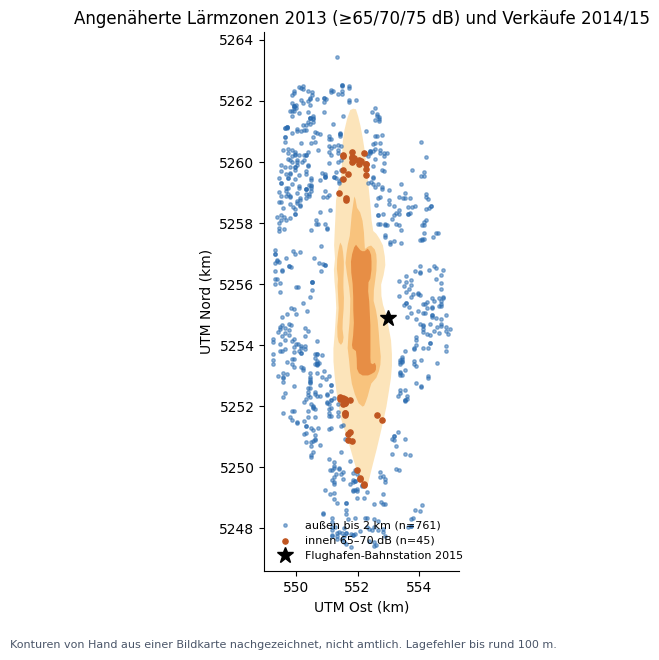

In [8]:
umfeld = df[df.grenze_signiert_m <= 2000]
fig, ax = plt.subplots(figsize=(7, 7))
for poly, farbe in [(zone[65], "#fbd38d"), (zone[70], "#f6ad55"), (zone[75], "#dd6b20")]:
    for teil in getattr(poly, "geoms", [poly]):
        ax.fill(*np.array(teil.exterior.xy) / 1000, color=farbe, alpha=0.6, linewidth=0)
aussen = umfeld[umfeld.laerm == 0]
innen = umfeld[umfeld.laerm == 1]
ax.scatter(aussen.x_m / 1000, aussen.y_m / 1000, s=6, color=BLAU, alpha=0.5, label=f"außen bis 2 km (n={len(aussen)})")
ax.scatter(innen.x_m / 1000, innen.y_m / 1000, s=14, color=ROT, label=f"innen 65–70 dB (n={len(innen)})")
st = json.load(open(f"{EINGABE}/airport_station_2015.geojson", encoding="utf-8"))["features"][0]["geometry"]["coordinates"]
sx, sy = nach_utm(*st)
ax.plot(sx / 1000, sy / 1000, marker="*", color="black", markersize=12, linestyle="none", label="Flughafen-Bahnstation 2015")
ax.set(title="Angenäherte Lärmzonen 2013 (≥65/70/75 dB) und Verkäufe 2014/15",
       xlabel="UTM Ost (km)", ylabel="UTM Nord (km)", aspect="equal")
ax.legend(loc="lower left", fontsize=8, frameon=False)
fig.text(0.01, 0.0, "Konturen von Hand aus einer Bildkarte nachgezeichnet, nicht amtlich. Lagefehler bis rund 100 m.", fontsize=8, color="#4a5568")
speichern(fig, "A1_laermzone_karte"); plt.show()

### A.2 Rohvergleich: County und lokales Umfeld

In [9]:
gebiete = {
    "King County": df.index == df.index,
    "Zone + 2 km Umfeld": df.grenze_signiert_m <= 2000,
    "Zone + 2 km, ohne 150-m-Grenzfälle": (df.grenze_signiert_m <= 2000) & (df.grenze_m > 150),
}
zeilen = []
for gebiet, maske in gebiete.items():
    for innen_wert, g in df[maske].groupby("laerm"):
        zeilen.append({"gebiet": gebiet, "zone": "innen 65–70 dB" if innen_wert else "außen", "n": len(g),
                       "median_preis": g.price.median(), "median_sqft": g.sqft_living.median(),
                       "median_grade": g.grade.median(), "median_preis_sqft": (g.price / g.sqft_living).median(),
                       "median_alter": g.alter.median()})
roh_laerm = pd.DataFrame(zeilen)
for gebiet in gebiete:
    g = roh_laerm[roh_laerm.gebiet == gebiet].set_index("zone")
    print(f"{gebiet:38s} Median innen/außen: {(g.median_preis['innen 65–70 dB'] / g.median_preis['außen'] - 1) * 100:+.1f} %")
roh_laerm

King County                            Median innen/außen: -51.6 %
Zone + 2 km Umfeld                     Median innen/außen: -16.2 %
Zone + 2 km, ohne 150-m-Grenzfälle     Median innen/außen: -19.2 %


,gebiet,zone,n,median_preis,median_sqft,median_grade,median_preis_sqft,median_alter
0,King County,außen,21552,450000.000,1920.000,7.000,244.828,39.000
1,King County,innen 65–70 dB,45,218000.000,1210.000,6.000,175.258,61.000
2,Zone + 2 km Umfeld,außen,761,260000.000,1560.000,7.000,171.958,57.000
3,Zone + 2 km Umfeld,innen 65–70 dB,45,218000.000,1210.000,6.000,175.258,61.000
4,"Zone + 2 km, ohne 150-m-Grenzfälle",außen,729,260000.000,1580.000,7.000,171.678,58.000
5,"Zone + 2 km, ohne 150-m-Grenzfälle",innen 65–70 dB,21,209977.000,1230.000,6.000,170.886,61.000


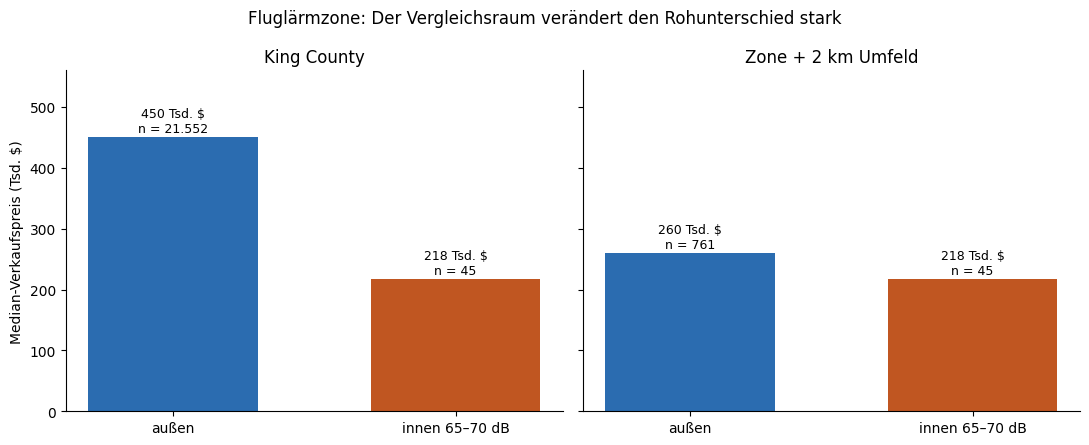

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, gebiet in zip(axes, ["King County", "Zone + 2 km Umfeld"]):
    g = roh_laerm[roh_laerm.gebiet == gebiet]
    balken = ax.bar(["außen", "innen 65–70 dB"], g.median_preis / 1000, color=[BLAU, ROT], width=0.6)
    for b, (_, r) in zip(balken, g.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 8, f"{r.median_preis / 1000:,.0f} Tsd. $\nn = {r.n:,}".replace(",", "."), ha="center", fontsize=9)
    ax.set(title=gebiet, ylim=(0, 560))
axes[0].set_ylabel("Median-Verkaufspreis (Tsd. $)")
fig.suptitle("Fluglärmzone: Der Vergleichsraum verändert den Rohunterschied stark")
plt.tight_layout(); speichern(fig, "A2_rohvergleich"); plt.show()

Gegen das ganze County wirkt der Unterschied riesig. Dieser Vergleich mischt aber völlig verschiedene Teilmärkte. Im lokalen Umfeld (Außenfälle bis 2 km von der Konturgrenze) ist er deutlich kleiner. Außerdem sind die Häuser in der Zone kleiner, älter und haben eine niedrigere Qualitätsnote. Ein Teil des Rohunterschieds kann also an den Häusern selbst liegen.

In [11]:
print("PLZ mit Innenfällen:", df[df.laerm == 1].zipcode.value_counts().to_dict())

PLZ mit Innenfällen: {98198: 23, 98168: 22}


### A.3 Modelle: Haus- und Lagekontrollen

Modell für den logarithmierten Preis. Der Koeffizient von „innen“ wird als prozentualer Preisunterschied bei sonst gleichen Merkmalen im Modell gelesen. Er ist nicht dasselbe wie der Unterschied der Rohmediane.

- **Hausmerkmale:** Wohn- und Grundstücksfläche, Schlafzimmer, Bäder, Etagen, Qualität, Zustand, Alter, Wasserlage, Aussicht, Verkaufsmonat.
- **Lage:** PLZ, zusätzlich ein glatter räumlicher Trend (Koordinaten, quadratisch) und die Entfernung zur Flughafen-Bahnstation.
- **Unsicherheit:** HC3-Standardfehler (Hauptvariante) und nach 1-km-Rasterzellen gruppierte Standardfehler (Sensitivität, weil benachbarte Häuser nicht unabhängig sind).

In [12]:
m = df[df.modell_ok].copy()
zx, zy = zone65.centroid.x, zone65.centroid.y
m["xkm"], m["ykm"] = (m.x_m - zx) / 1000, (m.y_m - zy) / 1000
m["station_km"] = np.hypot(m.x_m - sx, m.y_m - sy) / 1000
m["raster"] = (np.floor(m.x_m / 1000).astype(int).astype(str) + "_" + np.floor(m.y_m / 1000).astype(int).astype(str))
RAUM = "xkm + ykm + I(xkm**2) + I(ykm**2) + xkm:ykm"
lokal = m[m.grenze_signiert_m <= 2000]

spezifikationen = [
    ("County, roh", m, "laerm", ""),
    ("County + Haus + PLZ", m, "laerm", HAUS + " + C(zipcode)"),
    ("Lokal, roh", lokal, "laerm", ""),
    ("Lokal + Haus + PLZ", lokal, "laerm", HAUS + " + C(zipcode)"),
    ("Lokal + Haus + PLZ + Raum + Station", lokal, "laerm", HAUS + " + C(zipcode) + " + RAUM + " + station_km"),
    ("Ohne 150-m-Grenzfälle", lokal[lokal.grenze_m > 150], "laerm", HAUS + " + C(zipcode)"),
    ("Kontur 150 m eingezogen", lokal, "laerm_eingezogen150", HAUS + " + C(zipcode)"),
    ("Kontur 150 m erweitert", lokal, "laerm_erweitert150", HAUS + " + C(zipcode)"),
    ("Umfeld 1 km", m[m.grenze_signiert_m <= 1000], "laerm", HAUS + " + C(zipcode)"),
    ("Umfeld 5 km", m[m.grenze_signiert_m <= 5000], "laerm", HAUS + " + C(zipcode)"),
    ("Nur erster Verkauf je Haus", lokal.sort_values(["date", "sale_id"]).drop_duplicates("id"), "laerm", HAUS + " + C(zipcode)"),
]
zeilen = []
for name, daten, merkmal, kontrollen in spezifikationen:
    formel = f"lp ~ {merkmal}" + (f" + {kontrollen}" if kontrollen else "")
    for z in schaetzen(name, formel, daten, merkmal, {"HC3": None, "1-km-Raster": "raster"}):
        z["innen"] = int(daten[merkmal].sum())
        z["raster_mit_innen"] = daten.loc[daten[merkmal] == 1, "raster"].nunique()
        zeilen.append(z)
modelle_laerm = pd.DataFrame(zeilen)
modelle_laerm.round(3)

,modell,unsicherheit,n,prozent,ki_von,ki_bis,p,r2,innen,raster_mit_innen
0,"County, roh",HC3,21596,-53.262,-57.469,-48.639,0.000,0.004,45,11
1,"County, roh",1-km-Raster,21596,-53.262,-58.749,-47.045,0.000,0.004,45,11
2,County + Haus + PLZ,HC3,21596,-3.222,-9.462,3.447,0.335,0.886,45,11
3,County + Haus + PLZ,1-km-Raster,21596,-3.222,-7.923,1.718,0.197,0.886,45,11
4,"Lokal, roh",HC3,806,-18.313,-25.936,-9.905,0.000,0.015,45,11
5,"Lokal, roh",1-km-Raster,806,-18.313,-28.603,-6.539,0.004,0.015,45,11
6,Lokal + Haus + PLZ,HC3,806,-4.627,-11.284,2.529,0.199,0.717,45,11
7,Lokal + Haus + PLZ,1-km-Raster,806,-4.627,-10.116,1.197,0.115,0.717,45,11
8,Lokal + Haus + PLZ + Raum + Station,HC3,806,-0.763,-8.062,7.116,0.844,0.733,45,11
9,Lokal + Haus + PLZ + Raum + Station,1-km-Raster,806,-0.763,-6.141,4.923,0.785,0.733,45,11


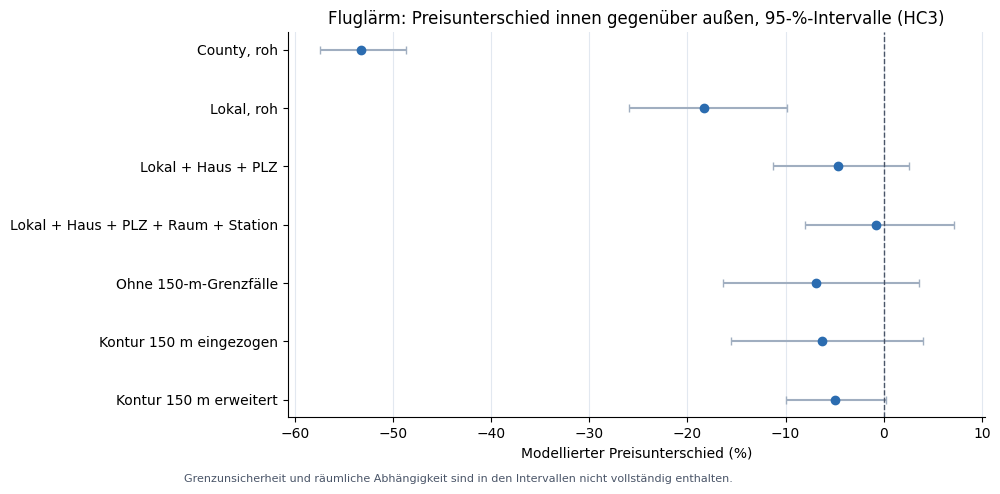

In [13]:
haupt = modelle_laerm[(modelle_laerm.unsicherheit == "HC3") & (modelle_laerm.modell != "County + Haus + PLZ")
                      & ~modelle_laerm.modell.str.startswith("Umfeld") & (modelle_laerm.modell != "Nur erster Verkauf je Haus")]
fig, ax = plt.subplots(figsize=(9, 5))
forest(ax, haupt, haupt.modell)
ax.set(title="Fluglärm: Preisunterschied innen gegenüber außen, 95-%-Intervalle (HC3)",
       xlabel="Modellierter Preisunterschied (%)")
fig.text(0.01, -0.02, "Grenzunsicherheit und räumliche Abhängigkeit sind in den Intervallen nicht vollständig enthalten.", fontsize=8, color="#4a5568")
speichern(fig, "A3_modelle"); plt.show()

### A.4 Ergebnis Fluglärm

**Beobachtet:**
- In der angenäherten 65-dB-Zone liegen 45 Verkäufe, in den Zonen ab 70 dB keiner. Alle Innenfälle stammen aus zwei PLZ (98198 und 98168) und 11 Rasterzellen von 1 km².
- Roh liegt der Median innen 16,2 % unter dem lokalen Umfeld (218.000 gegen 260.000 $). Gegen das ganze County wären es -51,6 %, das ist wegen der verschiedenen Teilmärkte kein sinnvoller Vergleich.
- Die Häuser in der Zone sind kleiner (1.210 gegen 1.560 sqft), älter (61 gegen 57 Jahre) und haben eine niedrigere Qualitätsnote (6 gegen 7). Pro sqft ist der Median fast gleich (175 gegen 172 $).

**Modelle:**
- Mit Hausmerkmalen und PLZ bleiben im lokalen Umfeld -4,6 % (95 % HC3: -11,3 bis +2,5 %). Mit räumlichem Trend und Stationsentfernung sind es -0,8 % (-8,1 bis +7,1 %).
- Alle Sensitivitätsprüfungen liegen zwischen -0,8 und -6,9 %. Die Punktschätzungen sind also durchgehend negativ, die HC3-Intervalle schließen aber überall 0 ein.
- Einzige Ausnahme: Kontur um 150 m erweitert, mit Rasterclusterung: -5,0 % (-9,4 bis -0,3 %). Das ist ein einzelner Befund unter vielen Varianten, nicht für Mehrfachtests korrigiert und mit HC3 nicht signifikant. Er trägt keine Aussage.

**Einordnung:** Der Rohpreisunterschied ist real, geht aber zu einem großen Teil auf kleinere, ältere und einfachere Häuser zurück. Ein eigenständiger Lärmabschlag lässt sich mit 45 Fällen und einer angenäherten Kontur nicht robust nachweisen. Das ist **kein** Nachweis, dass Fluglärm keinen Einfluss hat: Die Schätzungen sind unpräzise, und „außerhalb der Kontur“ heißt nicht „lärmfrei“. Kausal ist keine der Zahlen zu lesen.

## B. Boeing-Nähe (Ergänzung)

**Hypothese:** Die Entfernung zu den Boeing-Standorten Renton, Auburn und Kent hängt mit Hauspreisen zusammen. Kürzere Arbeitswege könnten einen Preisaufschlag für Nähe bedeuten. Das ist eine mögliche Erklärung, keine gemessene Eigenschaft: Arbeitgeber und Beruf der Käufer sind unbekannt.

**Abgrenzung:** Boeing Everett liegt in Snohomish County, außerhalb der Daten, und ist ausgeschlossen. Die Koordinaten stammen aus einem heutigen Behördenregister mit historischen Belegen für 2014. Bei Kent ist die historische Zuordnung unsicherer. Gemessen wird die Luftlinie zu einem Standortpunkt, keine Werkstore und keine Pendelzeit.

### B.1 Entfernungen und Rohpreise

In [14]:
boeing = json.load(open(f"{EINGABE}/boeing_reference_points.geojson", encoding="utf-8"))
STANDORTE = {}
for f in boeing["features"]:
    s = f["properties"]["site_id"].removeprefix("boeing_")
    if s == "everett":
        continue
    lon, lat = f["geometry"]["coordinates"]
    STANDORTE[s] = (lat, lon)
    df[f"boeing_{s}_km"] = haversine_km(df.lat, df.long, lat, lon)
print(STANDORTE)
df[[f"boeing_{s}_km" for s in STANDORTE]].describe().T[["min", "50%", "max"]]

{'renton': (47.499474, -122.20533), 'auburn': (47.288574, -122.242645), 'kent': (47.421772, -122.251785)}


,min,50%,max
boeing_renton_km,0.866,18.613,70.845
boeing_auburn_km,0.636,34.580,84.162
boeing_kent_km,1.563,21.725,77.384


In [15]:
zeilen = []
for s in STANDORTE:
    band = pd.cut(df[f"boeing_{s}_km"], [-np.inf, 5, 10, 20, np.inf], labels=["0–5 km", "5–10 km", "10–20 km", "über 20 km"])
    for b, g in df.groupby(band, observed=True):
        zeilen.append({"standort": s, "entfernung": str(b), "n": len(g), "median_preis": g.price.median(),
                       "median_sqft": g.sqft_living.median(), "median_preis_sqft": (g.price / g.sqft_living).median()})
roh_boeing = pd.DataFrame(zeilen)
korr_boeing = pd.DataFrame({s: {"Spearman Entfernung–Preis": spearmanr(df[f"boeing_{s}_km"], df.price).statistic,
                                "Pearson Entfernung–log(Preis)": df[f"boeing_{s}_km"].corr(df.lp)} for s in STANDORTE}).T
print(korr_boeing.round(3))
print("\nKorrelation der drei Entfernungen untereinander:")
print(df[[f"boeing_{s}_km" for s in STANDORTE]].corr().round(3))
roh_boeing

        Spearman Entfernung–Preis  Pearson Entfernung–log(Preis)
renton                      0.046                          0.023
auburn                      0.448                          0.445
kent                        0.382                          0.334

Korrelation der drei Entfernungen untereinander:
                  boeing_renton_km  boeing_auburn_km  boeing_kent_km
boeing_renton_km             1.000             0.474           0.808
boeing_auburn_km             0.474             1.000           0.879
boeing_kent_km               0.808             0.879           1.000


,standort,entfernung,n,median_preis,median_sqft,median_preis_sqft
0,renton,0–5 km,1189,350000.000,1940.000,194.853
1,renton,5–10 km,2592,379250.000,1960.000,213.863
2,renton,10–20 km,8296,485000.000,1960.000,257.999
3,renton,über 20 km,9520,458000.000,1860.000,248.053
4,auburn,0–5 km,521,250600.000,1780.000,145.963
5,auburn,5–10 km,1213,275900.000,1870.000,150.538
6,auburn,10–20 km,2860,302500.000,1870.000,165.968
7,auburn,über 20 km,17003,515000.000,1940.000,270.833
8,kent,0–5 km,416,275000.000,1760.000,159.904
9,kent,5–10 km,2530,289000.000,1770.000,167.360


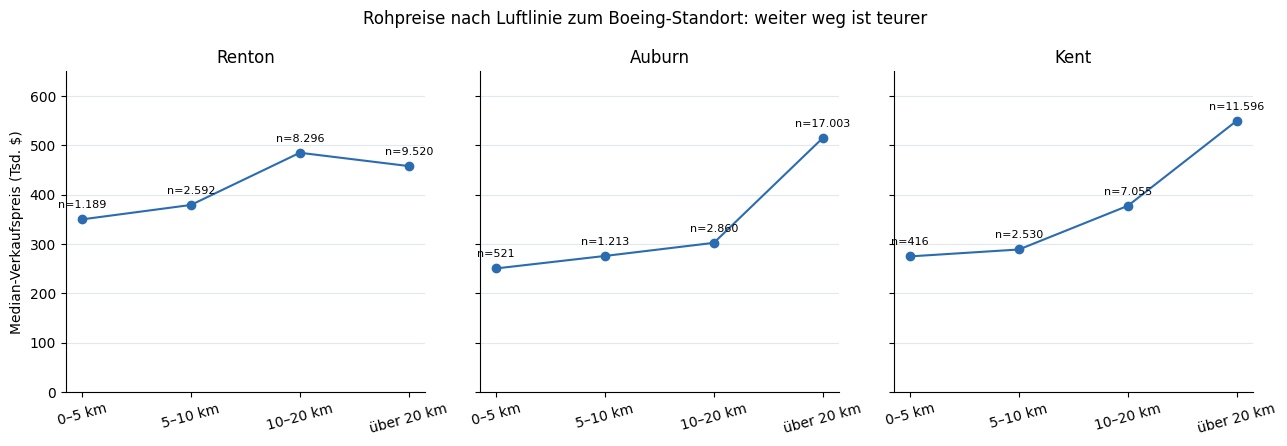

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for ax, s in zip(axes, STANDORTE):
    g = roh_boeing[roh_boeing.standort == s]
    ax.plot(range(len(g)), g.median_preis / 1000, "o-", color=BLAU)
    for i, (_, r) in enumerate(g.iterrows()):
        ax.annotate(f"n={r.n:,}".replace(",", "."), (i, r.median_preis / 1000), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(g)), g.entfernung, rotation=15)
    ax.set(title=s.title(), ylim=(0, 650))
    ax.grid(axis="y", color="#e2e8f0")
axes[0].set_ylabel("Median-Verkaufspreis (Tsd. $)")
fig.suptitle("Rohpreise nach Luftlinie zum Boeing-Standort: weiter weg ist teurer")
plt.tight_layout(); speichern(fig, "B1_rohpreise"); plt.show()

Roh sind Häuser nahe den Werken günstiger. Die drei Werke liegen aber alle im Süden des Countys, wo die Preise ohnehin niedriger sind (siehe Review-Notebook, H2). Die Entfernung zu einem Werk ist also auch eine Entfernung zu den teuren Lagen im Norden. Die drei Entfernungen hängen außerdem stark miteinander zusammen.

### B.2 Modelle
Je Standort ein eigenes Modell, Entfernung pro 5 km. Ein negativer Wert heißt: weiter weg ist günstiger, also ein Aufschlag für Nähe. Standardfehler nach PLZ gruppiert. Der räumliche Trend ist ein kubisches Polynom der Koordinaten.

In [17]:
m = m.join(df[[f"boeing_{s}_km" for s in STANDORTE]])   # Entfernungen wurden nach dem Anlegen von m berechnet
m["latc"], m["lonc"] = m.lat - 47.5, m.long + 122.2
RAUM_B = ("latc + lonc + I(latc**2) + I(lonc**2) + latc:lonc + I(latc**3) + I(lonc**3) "
          "+ I(latc**2):lonc + latc:I(lonc**2)")
zeilen = []
for s in STANDORTE:
    m["entf5"] = m[f"boeing_{s}_km"] / 5
    preis_1_99 = m.price.between(m.price.quantile(0.01), m.price.quantile(0.99))
    spez = [
        ("Roh", m, ""),
        ("+ Haus", m, HAUS),
        ("+ Haus + PLZ", m, HAUS + " + C(zipcode)"),
        ("+ Haus + PLZ + Raumtrend", m, HAUS + " + C(zipcode) + " + RAUM_B),
        ("Nur bis 15 km", m[m[f"boeing_{s}_km"] <= 15], HAUS + " + C(zipcode)"),
        ("Nur erster Verkauf je Haus", m.sort_values(["date", "sale_id"]).drop_duplicates("id"), HAUS + " + C(zipcode)"),
        ("Ohne 1 % teuerste/günstigste", m[preis_1_99], HAUS + " + C(zipcode)"),
    ]
    for name, daten, kontrollen in spez:
        formel = "lp ~ entf5" + (f" + {kontrollen}" if kontrollen else "")
        for z in schaetzen(name, formel, daten, "entf5", {"PLZ-Cluster": "zipcode"}):
            z["standort"] = s
            zeilen.append(z)
modelle_boeing = pd.DataFrame(zeilen)
modelle_boeing.pivot(index="modell", columns="standort", values="prozent").loc[[x[0] for x in spez]].round(1)

standort,auburn,kent,renton
modell,,,
Roh,8.800,9.100,0.800
+ Haus,6.700,6.800,1.800
+ Haus + PLZ,0.600,-1.200,-2.900
+ Haus + PLZ + Raumtrend,3.500,21.200,13.400
Nur bis 15 km,2.600,8.300,10.200
Nur erster Verkauf je Haus,0.700,-1.200,-2.900
Ohne 1 % teuerste/günstigste,0.600,-1.300,-3.100


In [18]:
modelle_boeing.round(3)

,modell,unsicherheit,n,prozent,ki_von,ki_bis,p,r2,standort
0,Roh,PLZ-Cluster,21596,0.763,-4.390,6.193,0.774,0.001,renton
1,+ Haus,PLZ-Cluster,21596,1.790,-0.944,4.600,0.198,0.666,renton
2,+ Haus + PLZ,PLZ-Cluster,21596,-2.935,-5.430,-0.373,0.026,0.887,renton
3,+ Haus + PLZ + Raumtrend,PLZ-Cluster,21596,13.424,4.781,22.779,0.002,0.891,renton
4,Nur bis 15 km,PLZ-Cluster,7732,10.236,1.383,19.863,0.024,0.887,renton
5,Nur erster Verkauf je Haus,PLZ-Cluster,21419,-2.909,-5.400,-0.353,0.027,0.887,renton
6,Ohne 1 % teuerste/günstigste,PLZ-Cluster,21167,-3.140,-5.611,-0.604,0.016,0.879,renton
7,Roh,PLZ-Cluster,21596,8.788,6.419,11.209,0.000,0.198,auburn
8,+ Haus,PLZ-Cluster,21596,6.720,5.295,8.164,0.000,0.770,auburn
9,+ Haus + PLZ,PLZ-Cluster,21596,0.631,-3.660,5.112,0.774,0.886,auburn


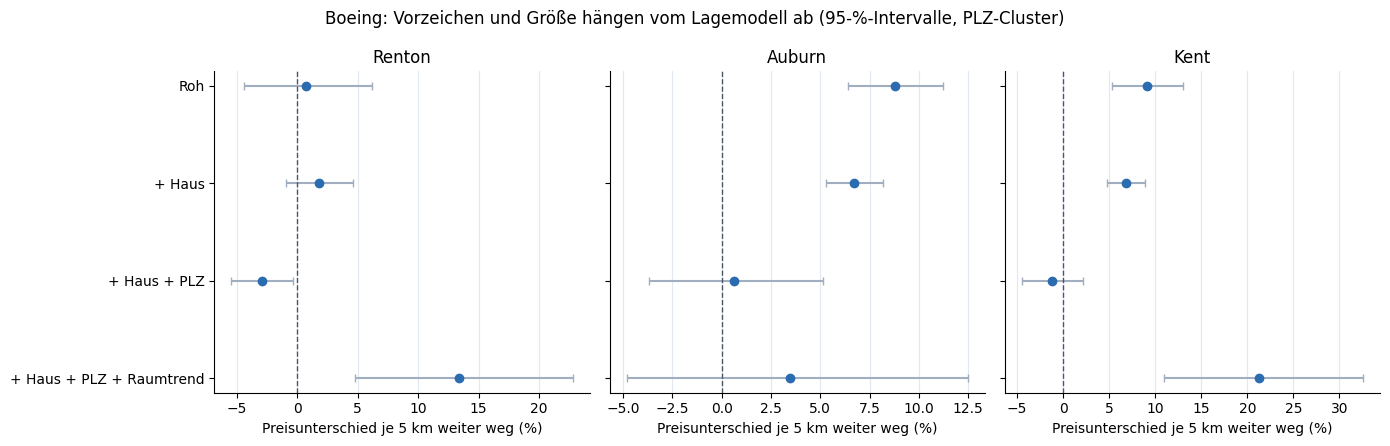

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
namen = ["Roh", "+ Haus", "+ Haus + PLZ", "+ Haus + PLZ + Raumtrend"]
for ax, s in zip(axes, STANDORTE):
    g = modelle_boeing[(modelle_boeing.standort == s) & modelle_boeing.modell.isin(namen)].set_index("modell").loc[namen].reset_index()
    forest(ax, g, namen)
    ax.set(title=s.title(), xlabel="Preisunterschied je 5 km weiter weg (%)")
fig.suptitle("Boeing: Vorzeichen und Größe hängen vom Lagemodell ab (95-%-Intervalle, PLZ-Cluster)")
plt.tight_layout(); speichern(fig, "B2_modelle"); plt.show()

### B.3 Ergebnis Boeing

**Beobachtet:**
- Roh sind Häuser nahe Auburn und Kent deutlich günstiger. Median 0 bis 5 km gegen über 20 km: Auburn 250.600 gegen 515.000 $, Kent 275.000 gegen 549.925 $. Bei Renton ist der Verlauf flacher (350.000 gegen 458.000 $, mit dem höchsten Wert bei 10 bis 20 km).
- Die drei Entfernungen hängen stark zusammen (Kent mit Auburn 0,88, mit Renton 0,81). Separate Modelle trennen also keine unabhängigen Werkseffekte.

**Modelle, je 5 km weiter weg** (in der Grafik hat jedes Feld eine eigene x-Skala):
- Roh: Auburn +8,8 %, Kent +9,1 %, Renton +0,8 %.
- Mit Hausmerkmalen und PLZ: Auburn +0,6 % (-3,7 bis +5,1), Kent -1,2 % (-4,5 bis +2,2), Renton -2,9 % (-5,4 bis -0,4).
- Zusätzlich räumlicher Trend: Renton +13,4 % (4,8 bis 22,8), Kent +21,2 % (10,9 bis 32,6), Auburn +3,5 % (-4,8 bis +12,5).
- Nur bis 15 km Entfernung: Renton +10,2 %, Kent +8,3 %, Auburn +2,6 %. Erster Verkauf je Haus und ohne Preisausreißer ändern kaum etwas.

**Einordnung:** Der große Rohunterschied spiegelt vor allem das Preisgefälle zwischen Nord und Süd im County. Nach Kontrolle der PLZ verschwindet er weitgehend. Bei Renton dreht sich das Vorzeichen je nach Lagemodell: Ein Näheaufschlag (-2,9 % je 5 km) wird mit räumlichem Trend zu einem Näheabschlag (+13,4 %). Die Entfernung zu einem Werk ist selbst eine Funktion der Lage, zusätzliche Koordinatenterme lösen dieses Problem nicht. Ein höheres R² (0,887 gegen 0,891) heißt nicht, dass Lage und Werk besser getrennt sind. **Ergebnis: kein robuster eigenständiger Boeing-Näheeffekt.** Die Pendel-Erklärung bleibt eine Vermutung.

## C. Flughafenbahn Central Link 2015 (explorativ)

**Hypothese:** Häuser bis 800 m Luftlinie von einer 2014/15 betriebenen Central-Link-Station erzielen höhere Preise als vergleichbare Häuser 800 m bis 3 km von der nächsten Station.

**Abgrenzung:** 13 Stationen waren 2014/15 in Betrieb (Sound Transit 2015). Capitol Hill, University of Washington und Angle Lake eröffneten später und fehlen. Koordinaten aus OpenStreetMap, Stand 01.01.2015 (© OpenStreetMap contributors, ODbL). Gemessen wird die Luftlinie zum Stationspunkt, nicht Gehzeit oder Zugang. Nähe zur Bahn heißt auch Nähe zu Downtown und anderen Arbeitsplätzen. Zusätzlich: Luftlinie zur Station am Flughafen als Maß für Flughafennähe, nicht für Anbindung.

### C.1 Stationen und Rohpreise

In [20]:
stationen = pd.read_csv(f"{EINGABE}/link_stations_2015.csv")
print("Stationen:", len(stationen))
abstaende = np.column_stack([haversine_km(df.lat, df.long, s.lat, s.lon) for s in stationen.itertuples()])
df["link_km"] = abstaende.min(axis=1)
df["station"] = stationen.name.to_numpy()[abstaende.argmin(axis=1)]
flughafen = stationen[stationen.name == "SeaTac/Airport"].iloc[0]
df["flughafen_km"] = haversine_km(df.lat, df.long, flughafen.lat, flughafen.lon)
for meter in [500, 800, 1000]:
    df[f"nah{meter}"] = (df.link_km <= meter / 1000).astype(int)

abdeckung = df.groupby("station").agg(verkaeufe_naechste=("sale_id", "size"), bis_800m=("nah800", "sum")).sort_values("bis_800m", ascending=False)
abdeckung

Stationen: 13


,verkaeufe_naechste,bis_800m
station,,
Columbia City,400,75
Othello,1886,70
Mount Baker,2703,62
Beacon Hill,106,41
Rainier Beach,2287,31
Tukwila International Boulevard,1466,13
SeaTac/Airport,4523,6
Stadium,22,2
International District/Chinatown,188,0


In [21]:
zeilen = []
for merkmal, grenzen, namen in [("link_km", [-np.inf, 0.8, 3, np.inf], ["bis 800 m", "800 m bis 3 km", "über 3 km"]),
                                ("flughafen_km", [-np.inf, 5, 10, 20, np.inf], ["0–5 km", "5–10 km", "10–20 km", "über 20 km"])]:
    for b, g in df.groupby(pd.cut(df[merkmal], grenzen, labels=namen), observed=True):
        zeilen.append({"merkmal": merkmal, "gruppe": str(b), "n": len(g), "median_preis": g.price.median(),
                       "median_sqft": g.sqft_living.median(), "median_grade": g.grade.median()})
roh_link = pd.DataFrame(zeilen)
g = roh_link[roh_link.merkmal == "link_km"].set_index("gruppe")
print(f"Median bis 800 m gegenüber 800 m bis 3 km: {(g.median_preis['bis 800 m'] / g.median_preis['800 m bis 3 km'] - 1) * 100:+.1f} %")
roh_link

Median bis 800 m gegenüber 800 m bis 3 km: -9.0 %


,merkmal,gruppe,n,median_preis,median_sqft,median_grade
0,link_km,bis 800 m,300,375000.000,1660.000,7.000
1,link_km,800 m bis 3 km,1503,412000.000,1620.000,7.000
2,link_km,über 3 km,19794,455000.000,1940.000,7.000
3,flughafen_km,0–5 km,581,275000.000,1580.000,7.000
4,flughafen_km,5–10 km,2056,280000.000,1635.000,7.000
5,flughafen_km,10–20 km,7138,396837.500,1911.000,7.000
6,flughafen_km,über 20 km,11822,528000.000,1990.000,8.000


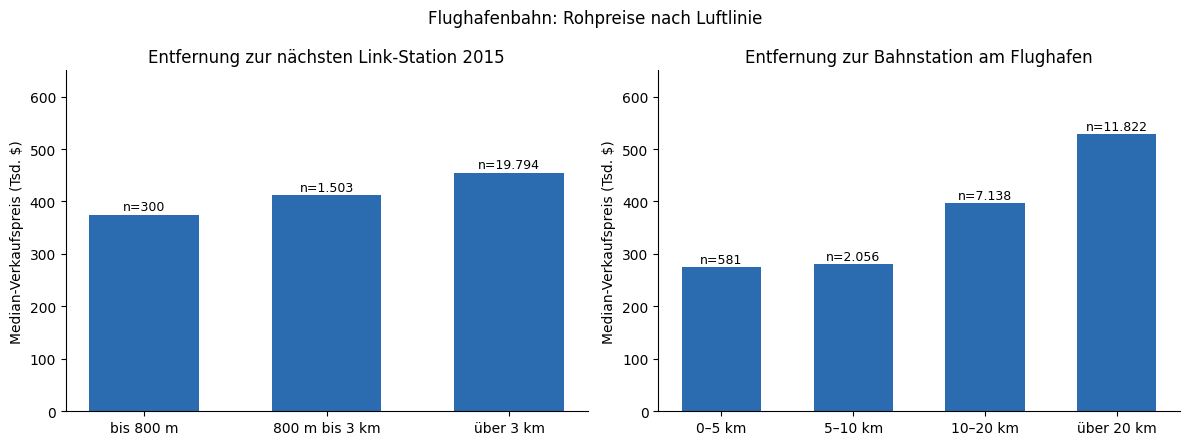

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, merkmal, titel in zip(axes, ["link_km", "flughafen_km"], ["Entfernung zur nächsten Link-Station 2015", "Entfernung zur Bahnstation am Flughafen"]):
    g = roh_link[roh_link.merkmal == merkmal]
    balken = ax.bar(g.gruppe, g.median_preis / 1000, color=BLAU, width=0.6)
    for b, (_, r) in zip(balken, g.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 8, f"n={r.n:,}".replace(",", "."), ha="center", fontsize=9)
    ax.set(title=titel, ylim=(0, 650), ylabel="Median-Verkaufspreis (Tsd. $)")
fig.suptitle("Flughafenbahn: Rohpreise nach Luftlinie")
plt.tight_layout(); speichern(fig, "C1_rohpreise"); plt.show()

### C.2 Modelle

Lokaler Vergleich nur im Korridor bis 3 km um die Stationen. Kontrollen: Hausmerkmale, Gebiet der nächsten Station, PLZ, Lärmzone aus Teil A, zusätzlich ein quadratischer räumlicher Trend und die Flughafenentfernung. Standardfehler nach PLZ gruppiert (Hauptvariante), HC3 als Sensitivität. Stationsgebiet und PLZ überlappen teilweise. statsmodels rechnet mit der Pseudoinverse, der Koeffizient der Nähe bleibt davon unberührt.

In [23]:
m = m.join(df[["link_km", "station", "flughafen_km", "nah500", "nah800", "nah1000"]])
m["flughafen5"] = m.flughafen_km / 5
RAUM_C = "latc + lonc + I(latc**2) + I(lonc**2) + latc:lonc"
korridor = m[m.link_km <= 3]
ST = HAUS + " + C(station)"
spez_link = [
    ("County, roh", m, "nah800", ""),
    ("Korridor, roh", korridor, "nah800", ""),
    ("+ Haus + Stationsgebiet", korridor, "nah800", ST),
    ("+ PLZ + Lärmzone", korridor, "nah800", ST + " + C(zipcode) + laerm"),
    ("+ Raumtrend + Flughafenentfernung", korridor, "nah800", ST + " + C(zipcode) + laerm + " + RAUM_C + " + flughafen5"),
    ("Schwelle 500 m", korridor, "nah500", ST + " + C(zipcode) + laerm"),
    ("Schwelle 1.000 m", korridor, "nah1000", ST + " + C(zipcode) + laerm"),
    ("Ohne Lärmzone und Grenzfälle", korridor[(korridor.laerm == 0) & (korridor.grenze_m > 150)], "nah800", ST + " + C(zipcode)"),
    ("Nur erster Verkauf je Haus", korridor.sort_values(["date", "sale_id"]).drop_duplicates("id"), "nah800", ST + " + C(zipcode) + laerm"),
]
spez_flughafen = [
    ("Flughafen: roh", m, "flughafen5", ""),
    ("Flughafen: + Haus", m, "flughafen5", HAUS),
    ("Flughafen: + PLZ + Lärmzone", m, "flughafen5", HAUS + " + C(zipcode) + laerm"),
    ("Flughafen: + Raumtrend", m, "flughafen5", HAUS + " + C(zipcode) + laerm + " + RAUM_C),
    ("Flughafen: nur bis 15 km", m[m.flughafen_km <= 15], "flughafen5", HAUS + " + C(zipcode) + laerm"),
]
zeilen = []
for name, daten, merkmal, kontrollen in spez_link + spez_flughafen:
    formel = f"lp ~ {merkmal}" + (f" + {kontrollen}" if kontrollen else "")
    for z in schaetzen(name, formel, daten, merkmal, {"PLZ-Cluster": "zipcode", "HC3": None}):
        z["nah"] = int(daten[merkmal].sum()) if merkmal.startswith("nah") else None
        z["plz"] = daten.zipcode.nunique()
        zeilen.append(z)
modelle_link = pd.DataFrame(zeilen)
modelle_link.round(3)

,modell,unsicherheit,n,prozent,ki_von,ki_bis,p,r2,nah,plz
0,"County, roh",PLZ-Cluster,21596,-19.831,-36.192,0.726,0.058,0.002,300.000,70
1,"County, roh",HC3,21596,-19.831,-23.174,-16.342,0.000,0.002,300.000,70
2,"Korridor, roh",PLZ-Cluster,1803,-12.993,-30.506,8.933,0.207,0.009,300.000,16
3,"Korridor, roh",HC3,1803,-12.993,-17.295,-8.467,0.000,0.009,300.000,16
4,+ Haus + Stationsgebiet,PLZ-Cluster,1803,-5.131,-10.487,0.545,0.072,0.856,300.000,16
5,+ Haus + Stationsgebiet,HC3,1803,-5.131,-7.739,-2.450,0.000,0.856,300.000,16
6,+ PLZ + Lärmzone,PLZ-Cluster,1803,-7.241,-10.704,-3.644,0.001,0.866,300.000,16
7,+ PLZ + Lärmzone,HC3,1803,-7.241,-9.812,-4.596,0.000,0.866,300.000,16
8,+ Raumtrend + Flughafenentfernung,PLZ-Cluster,1803,-1.995,-4.061,0.116,0.062,0.873,300.000,16
9,+ Raumtrend + Flughafenentfernung,HC3,1803,-1.995,-4.974,1.077,0.201,0.873,300.000,16


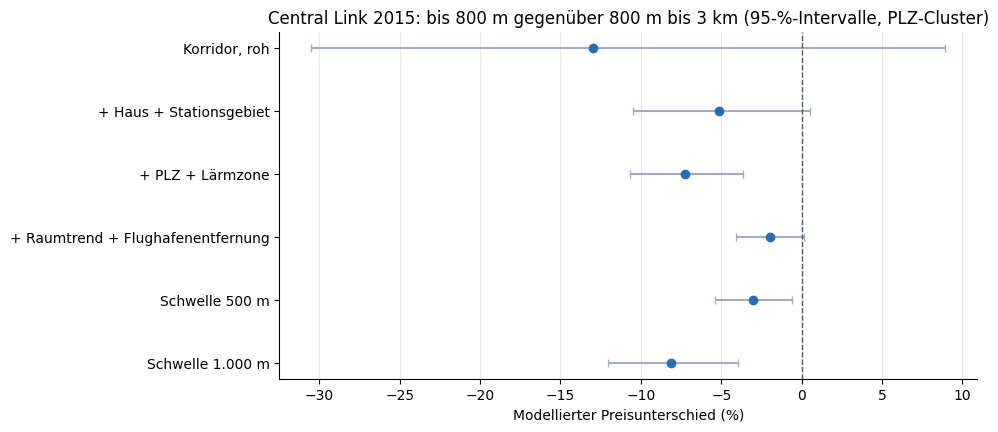

In [24]:
auswahl = ["Korridor, roh", "+ Haus + Stationsgebiet", "+ PLZ + Lärmzone", "+ Raumtrend + Flughafenentfernung", "Schwelle 500 m", "Schwelle 1.000 m"]
g = modelle_link[(modelle_link.unsicherheit == "PLZ-Cluster") & modelle_link.modell.isin(auswahl)].set_index("modell").loc[auswahl].reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
forest(ax, g, auswahl)
ax.set(title="Central Link 2015: bis 800 m gegenüber 800 m bis 3 km (95-%-Intervalle, PLZ-Cluster)",
       xlabel="Modellierter Preisunterschied (%)")
speichern(fig, "C2_modelle"); plt.show()

### C.3 Ergebnis Flughafenbahn

**Beobachtet:**
- 300 Verkäufe liegen bis 800 m von einer Station, 279 davon bei fünf Stationen im Süden (Columbia City 75, Othello 70, Mount Baker 62, Beacon Hill 41, Rainier Beach 31). Bei den Downtown-Stationen (Westlake, University Street, Pioneer Square, International District, SODO) gibt es keinen einzigen.
- Roh liegen stationsnahe Häuser 9,0 % unter dem Korridor 800 m bis 3 km (375.000 gegen 412.000 $). Ein Rohaufschlag zeigt sich nicht.

**Modelle (PLZ-Cluster):**
- Mit Hausmerkmalen und Stationsgebiet: -5,1 % (-10,5 bis +0,5). Zusätzlich PLZ und Lärmzone: -7,2 % (-10,7 bis -3,6). Zusätzlich räumlicher Trend und Flughafenentfernung: -2,0 % (-4,1 bis +0,1).
- Die Schwelle verändert die Größe deutlich: 500 m -3,0 %, 1.000 m -8,1 %.
- Der Korridor umfasst nur 16 PLZ. Bei so wenigen Clustern sind auch die gruppierten Intervalle unsicher, HC3 steht daneben in der Tabelle.
- **Flughafennähe** je 5 km weiter weg: roh +7,9 %, mit PLZ und Lärmzone -1,9 % (-4,9 bis +1,2), mit räumlichem Trend +18,5 %. Das Vorzeichen ist nicht stabil.

**Einordnung:** Die Hypothese eines Näheaufschlags wird nicht gestützt. Mehrere Varianten zeigen eher einen Abschlag, dessen Größe aber von Schwelle und Kontrollen abhängt. Das ist kein Nachweis, dass eine Bahnanbindung den Wert senkt: Gemessen wird nur die Luftlinie zu Stationspunkten, die nahen Verkäufe liegen fast alle in wenigen südlichen Vierteln, und Bahnnähe heißt auch Nähe zu Gewerbe und Straßen. Flughafennähe und Bahnanbindung lassen sich mit diesen Merkmalen nicht trennen.

## D. Vergleich mit den Referenzwerten der Übergabe

Die Referenzwerte stammen aus der Übergabe von ChatGPT/Codex (`infrastruktur_daten/UEBERGABE_referenzwerte.txt`). Sie wurden hier nicht übernommen, sondern unabhängig neu berechnet. Die Tabelle zeigt, ob die eigene Berechnung sie bestätigt.

In [25]:
def wert(tab, **filter_):
    t = tab
    for k, v in filter_.items():
        t = t[t[k] == v]
    return t.iloc[0]

rl = roh_laerm.set_index(["gebiet", "zone"])
lm = lambda name, u="HC3": wert(modelle_laerm, modell=name, unsicherheit=u)
bm = lambda s, name: wert(modelle_boeing, standort=s, modell=name)
km = lambda name, u="PLZ-Cluster": wert(modelle_link, modell=name, unsicherheit=u)
rb = roh_boeing.set_index(["standort", "entfernung"])
rk = roh_link.set_index(["merkmal", "gruppe"])

vergleich = pd.DataFrame([
    ("A Lärm: Verkäufe innen", 45, df.laerm.sum()),
    ("A Lärm: innen bei 150 m eingezogen / erweitert", "21 / 77", f"{df.laerm_eingezogen150.sum()} / {df.laerm_erweitert150.sum()}"),
    ("A Lärm: Median innen (Tsd. $)", 218.0, rl.loc[("Zone + 2 km Umfeld", "innen 65–70 dB"), "median_preis"] / 1000),
    ("A Lärm: Median außen bis 2 km (Tsd. $), n", "260.0, 761", f"{rl.loc[('Zone + 2 km Umfeld', 'außen'), 'median_preis'] / 1000:.1f}, {rl.loc[('Zone + 2 km Umfeld', 'außen'), 'n']}"),
    ("A Lärm: lokaler Medianunterschied %", -16.2, (rl.loc[("Zone + 2 km Umfeld", "innen 65–70 dB"), "median_preis"] / rl.loc[("Zone + 2 km Umfeld", "außen"), "median_preis"] - 1) * 100),
    ("A Lärm: lokal + Haus + PLZ % [KI]", "-4.6 [-11.3; 2.5]", f"{lm('Lokal + Haus + PLZ').prozent:.1f} [{lm('Lokal + Haus + PLZ').ki_von:.1f}; {lm('Lokal + Haus + PLZ').ki_bis:.1f}]"),
    ("A Lärm: + Raum + Station % [KI]", "-0.8 [-8.1; 7.1]", f"{lm('Lokal + Haus + PLZ + Raum + Station').prozent:.1f} [{lm('Lokal + Haus + PLZ + Raum + Station').ki_von:.1f}; {lm('Lokal + Haus + PLZ + Raum + Station').ki_bis:.1f}]"),
    ("A Lärm: ohne Grenzfälle % [KI]", "-6.9 [-16.4; 3.6]", f"{lm('Ohne 150-m-Grenzfälle').prozent:.1f} [{lm('Ohne 150-m-Grenzfälle').ki_von:.1f}; {lm('Ohne 150-m-Grenzfälle').ki_bis:.1f}]"),
    ("B Renton: Median 0–5 / über 20 km (Tsd. $)", "350.0 / 458.0", f"{rb.loc[('renton', '0–5 km'), 'median_preis'] / 1000:.1f} / {rb.loc[('renton', 'über 20 km'), 'median_preis'] / 1000:.1f}"),
    ("B Auburn: Median 0–5 / über 20 km (Tsd. $)", "250.6 / 515.0", f"{rb.loc[('auburn', '0–5 km'), 'median_preis'] / 1000:.1f} / {rb.loc[('auburn', 'über 20 km'), 'median_preis'] / 1000:.1f}"),
    ("B Kent: Median 0–5 / über 20 km (Tsd. $)", "275.0 / 549.95", f"{rb.loc[('kent', '0–5 km'), 'median_preis'] / 1000:.1f} / {rb.loc[('kent', 'über 20 km'), 'median_preis'] / 1000:.1f}"),
    *[(f"B {s.title()}: + Haus + PLZ, je 5 km % [KI]", ref, f"{bm(s, '+ Haus + PLZ').prozent:.1f} [{bm(s, '+ Haus + PLZ').ki_von:.1f}; {bm(s, '+ Haus + PLZ').ki_bis:.1f}]")
      for s, ref in [("renton", "-2.9 [-5.4; -0.4]"), ("auburn", "0.6 [-3.7; 5.1]"), ("kent", "-1.2 [-4.5; 2.2]")]],
    *[(f"B {s.title()}: + Raumtrend, je 5 km %", ref, f"{bm(s, '+ Haus + PLZ + Raumtrend').prozent:.1f}") for s, ref in [("renton", "13.4"), ("kent", "21.2")]],
    ("C Link: Verkäufe bis 800 m / 800 m–3 km", "300 / 1.503", f"{rk.loc[('link_km', 'bis 800 m'), 'n']} / {rk.loc[('link_km', '800 m bis 3 km'), 'n']}"),
    ("C Link: Median bis 800 m / 800 m–3 km (Tsd. $)", "375.0 / 412.0", f"{rk.loc[('link_km', 'bis 800 m'), 'median_preis'] / 1000:.1f} / {rk.loc[('link_km', '800 m bis 3 km'), 'median_preis'] / 1000:.1f}"),
    ("C Link: + PLZ + Lärmzone % [KI]", "-7.2 [-10.7; -3.6]", f"{km('+ PLZ + Lärmzone').prozent:.1f} [{km('+ PLZ + Lärmzone').ki_von:.1f}; {km('+ PLZ + Lärmzone').ki_bis:.1f}]"),
    ("C Link: + Raumtrend + Flughafen % [KI]", "-2.0 [-4.1; 0.1]", f"{km('+ Raumtrend + Flughafenentfernung').prozent:.1f} [{km('+ Raumtrend + Flughafenentfernung').ki_von:.1f}; {km('+ Raumtrend + Flughafenentfernung').ki_bis:.1f}]"),
    ("C Flughafen: + PLZ + Lärm, je 5 km % [KI]", "-1.9 [-4.9; 1.2]", f"{km('Flughafen: + PLZ + Lärmzone').prozent:.1f} [{km('Flughafen: + PLZ + Lärmzone').ki_von:.1f}; {km('Flughafen: + PLZ + Lärmzone').ki_bis:.1f}]"),
    ("C Flughafen: + Raumtrend, je 5 km %", "18.5", f"{km('Flughafen: + Raumtrend').prozent:.1f}"),
], columns=["Kennzahl", "Übergabe", "eigene Berechnung"])
vergleich

,Kennzahl,Übergabe,eigene Berechnung
0,A Lärm: Verkäufe innen,45,45
1,A Lärm: innen bei 150 m eingezogen / erweitert,21 / 77,21 / 77
2,A Lärm: Median innen (Tsd. $),218.000,218.000
3,"A Lärm: Median außen bis 2 km (Tsd. $), n","260.0, 761","260.0, 761"
4,A Lärm: lokaler Medianunterschied %,-16.200,-16.154
5,A Lärm: lokal + Haus + PLZ % [KI],-4.6 [-11.3; 2.5],-4.6 [-11.3; 2.5]
6,A Lärm: + Raum + Station % [KI],-0.8 [-8.1; 7.1],-0.8 [-8.1; 7.1]
7,A Lärm: ohne Grenzfälle % [KI],-6.9 [-16.4; 3.6],-6.9 [-16.4; 3.6]
8,B Renton: Median 0–5 / über 20 km (Tsd. $),350.0 / 458.0,350.0 / 458.0
9,B Auburn: Median 0–5 / über 20 km (Tsd. $),250.6 / 515.0,250.6 / 515.0


**Ergebnis des Vergleichs:** Alle 22 Referenzwerte sind mit der eigenen Berechnung reproduziert.

Einzige Abweichung: Kent, Median über 20 km. Der Übergabetext nennt 549.950 $, die eigene Berechnung 549.925 $ (11.596 Verkäufe). Die Ergebnistabelle der Übergabe (`preis_nach_entfernung.csv`) nennt ebenfalls 549.925 $. Die 549.950 $ ergeben sich nur mit den auf 0,001 km gerundeten Entfernungen der Zusatzdatei: Dort fällt ein Verkauf an der 20-km-Grenze in die andere Gruppe (11.595 Verkäufe). Es ist eine Rundungsfrage im Übergabetext, keine inhaltliche Abweichung.

**Abweichungen im Vorgehen gegenüber der Übergabe:**
- Alle Merkmale (Lärmzone, Grenzabstände, Puffer, Boeing- und Stationsentfernungen) wurden aus den Geometrien neu berechnet. Die Zusatzdateien mit fertigen Merkmalen wurden nicht verwendet.
- Die Übergabe schlug vor, die Analysen in das Review-Notebook einzubauen. Auf Wunsch des Autors stehen sie stattdessen in diesem eigenen Notebook.
- Für die Bahnmodelle entfernt die Übergabe redundante Dummy-Spalten per QR-Zerlegung. Hier rechnet statsmodels mit der Pseudoinverse. Die Koeffizienten der Nähe sind identisch.
- Wie in der Übergabe gibt es kein gemeinsames Modell aller drei Merkmale. Die Teile überschneiden sich räumlich (dieselben Verkäufe im Süden), Effekte dürfen nicht addiert werden.

## E. Gemeinsame Erkenntnis und Grenzen

**Gemeinsame Erkenntnis:** Rohpreisunterschiede sind bei allen drei Merkmalen sichtbar. Nach Berücksichtigung von Hausmerkmalen und Lage werden sie deutlich kleiner oder hängen stark von der Modellwahl ab. Ein eigenständiger Einfluss von Fluglärm, Boeing-Nähe oder Bahnanbindung lässt sich mit diesen Daten nicht robust isolieren.

**Was das methodisch zeigt:**
1. Der Vergleichsraum entscheidet: County gegen lokales Umfeld ändert das Ergebnis von -52 % auf -16 % (Fluglärm).
2. Hausmerkmale erklären viel: In der Lärmzone sind die Häuser kleiner und älter.
3. Lage und Standortmerkmal sind verwoben: Bei Boeing dreht ein räumlicher Trend das Vorzeichen.
4. Unsicherheit gehört dazu: Intervalle, Grenzszenarien und mehrere Fehlerarten zeigen, wie fragil einzelne signifikante Werte sind.

**Zusammenhang, nicht Ursache:** Es sind Beobachtungsdaten aus einem Jahr. Häuser werden nicht zufällig in Lärmzonen oder an Bahnstationen gebaut. Für eine kausale Aussage bräuchte es zum Beispiel Verkäufe desselben Hauses vor und nach einer Änderung (etwa der Eröffnung einer Station oder einer neuen Flugroute), amtliche Lärmkonturen und Pendeldaten.

**Nicht als Ergebnis verwenden:**
- „Fluglärm senkt Hauspreise um 16 %.“ Das ist ein Roh-Medianunterschied.
- „Boeing-Nähe erhöht oder senkt Preise um X %.“ Werk und Lage sind nicht getrennt.
- „Eine Bahnanbindung senkt den Wert.“ Gemessen wurde nur Luftlinie zu Stationspunkten.
- „Nicht signifikant heißt kein Effekt.“ Die Schätzungen sind teils sehr unpräzise.

**Grenzen:** Lärmkonturen angenähert aus einer Karte von 2013, keine Verkäufe ab 70 dB, nur zwei PLZ mit Innenfällen. Boeing-Standorte als Referenzpunkte, Everett außerhalb der Daten. Bahn als Luftlinie zu 13 Stationspunkten. Die Modellvarianten wurden explorativ gewählt, nicht vorab festgelegt.

Quellen: Lärmkarte Seattle-Tacoma International Airport, Noise Exposure Map 2013. Stationsliste Sound Transit 2015. Koordinaten © OpenStreetMap contributors, ODbL. Boeing-Standorte aus Behördenregister mit Belegen für 2014 (siehe `infrastruktur_daten/`).

In [26]:
sha_nachher = hashlib.sha256(open(QUELLE, "rb").read()).hexdigest()
print("Original-CSV unverändert:", sha_vorher == sha_nachher)
print("Exportierte Grafiken:", sorted(os.listdir(AUSGABE)))

Original-CSV unverändert: True
Exportierte Grafiken: ['A1_laermzone_karte.png', 'A2_rohvergleich.png', 'A3_modelle.png', 'B1_rohpreise.png', 'B2_modelle.png', 'C1_rohpreise.png', 'C2_modelle.png']
